# E8 파생변수: 대체 모델 비교와 앙상블 평가

이 노트북은 XGBoost와 기존에 만든 ExtraTrees를 제외하고, **RandomForest**와 **HistGradientBoosting**을 대체 후보로 평가합니다. 두 모델의 예측 확률을 평균하는 **soft-voting 앙상블**도 함께 비교합니다. 모든 후보는 E8 파생변수, Macro F1, 동일한 grouped split을 사용하므로 점수표를 직접 비교할 수 있습니다.

완전 동일 변이 프로필을 그룹화해 별도 홀드아웃을 남겨 두고, 개발 데이터에서 4-fold grouped CV를 수행합니다. 앙상블은 두 후보의 클래스 확률을 균등 평균합니다. 단일 홀드아웃 결과로 향상을 확정하지 않으며, Macro F1뿐 아니라 균형 정확도와 weighted F1도 같이 확인합니다.

In [1]:
from pathlib import Path
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import f1_score, balanced_accuracy_score, accuracy_score, make_scorer, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_sample_weight

cwd = Path.cwd()
project_root = next((p for p in (cwd, cwd.parent) if (p / "src" / "features.py").is_file()), None)
if project_root is None:
    raise FileNotFoundError("프로젝트 루트에서 src/features.py를 찾을 수 없습니다.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src.features import build_features, gene_columns

train = pd.read_csv(project_root / "data" / "train.csv")
if "SUBCLASS" not in train.columns:
    raise KeyError("train.csv에 SUBCLASS 타깃 열이 없습니다.")
y_all = train["SUBCLASS"].astype("string").str.strip()
valid_target = y_all.notna() & y_all.ne("")
missing_target_count = int((~valid_target).sum())
train = train.loc[valid_target].reset_index(drop=True)
y = train["SUBCLASS"].astype(str)
genes = gene_columns(train)
if not genes:
    raise ValueError("학습 데이터에서 유전자 열을 찾을 수 없습니다.")
missing_gene_cells = int(train[genes].isna().sum().sum())
groups = pd.util.hash_pandas_object(train[genes].fillna("WT"), index=False).to_numpy()
class_labels = sorted(y.unique())
SEED = 42
print(f"Train: {len(train):,} rows, {len(genes):,} genes, {len(class_labels)} cancer classes")
print(f"Rows without target removed: {missing_target_count:,}; missing gene cells: {missing_gene_cells:,}")
print(f"Duplicate mutation profiles: {pd.Series(groups).duplicated().sum():,}")
display(y.value_counts().rename("sample_count").to_frame())

Train: 6,201 rows, 4,384 genes, 26 cancer classes
Rows without target removed: 0; missing gene cells: 0
Duplicate mutation profiles: 565


,sample_count
SUBCLASS,
BRCA,786
KIPAN,515
GBMLGG,461
STES,379
KIRC,334
THCA,324
SKCM,276
PRAD,266
OV,253


### 데이터 확인

이 셀은 클래스 빈도와 입력 결측을 확인합니다. 타깃 결측 행은 학습 대상에서 제외하고, 유전자 결측은 `build_features`의 기존 E8 규칙에 따라 WT로 처리합니다. 동일 유전자 프로필은 그룹으로 묶어 검증 fold 간 중복으로 점수가 부풀려지지 않도록 합니다.

In [2]:
N_SPLITS = 4
HOLDOUT_SPLITS = 5

outer_cv = StratifiedGroupKFold(n_splits=HOLDOUT_SPLITS, shuffle=True, random_state=SEED)
dev_idx, holdout_idx = next(outer_cv.split(train, y, groups))
dev = train.iloc[dev_idx].reset_index(drop=True)
holdout = train.iloc[holdout_idx].reset_index(drop=True)
y_dev = y.iloc[dev_idx].reset_index(drop=True)
y_holdout = y.iloc[holdout_idx].reset_index(drop=True)
groups_dev = groups[dev_idx]

# Build holdout features with development-only gene selection.
X_dev, X_holdout = build_features(dev, holdout, level="E8")
if list(X_dev.columns) != list(X_holdout.columns):
    raise ValueError("개발/홀드아웃 파생변수 열이 일치하지 않습니다.")

model_names = ["RandomForest", "HistGradientBoosting", "SoftVoting(RF+HGB)"]
oof_probabilities = {
    name: np.zeros((len(dev), len(class_labels)), dtype=np.float32)
    for name in model_names
}
fold_records = []

def make_candidates():
    return {
        "RandomForest": RandomForestClassifier(
            n_estimators=400,
            max_features="sqrt",
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            random_state=SEED,
            n_jobs=-1,
        ),
        "HistGradientBoosting": HistGradientBoostingClassifier(
            learning_rate=0.08,
            max_iter=160,
            max_leaf_nodes=15,
            min_samples_leaf=20,
            l2_regularization=1.0,
            early_stopping=False,
            random_state=SEED,
        ),
    }

def align_probabilities(model, X, labels):
    probabilities = model.predict_proba(X)
    aligned = np.zeros((len(X), len(labels)), dtype=np.float32)
    label_to_position = {label: index for index, label in enumerate(labels)}
    for model_position, label in enumerate(model.classes_):
        aligned[:, label_to_position[label]] = probabilities[:, model_position]
    return aligned

inner_cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED + 1)
for fold, (fit_idx, valid_idx) in enumerate(inner_cv.split(dev, y_dev, groups_dev), start=1):
    fold_train = dev.iloc[fit_idx].reset_index(drop=True)
    fold_valid = dev.iloc[valid_idx].reset_index(drop=True)
    X_fold_train, X_fold_valid = build_features(fold_train, fold_valid, level="E8")
    y_fold_train = y_dev.iloc[fit_idx]
    y_fold_valid = y_dev.iloc[valid_idx]
    if list(X_fold_train.columns) != list(X_fold_valid.columns):
        raise ValueError(f"Fold {fold}: 학습/검증 특성 열이 일치하지 않습니다.")

    fold_probabilities = {}
    for name, estimator in make_candidates().items():
        fit_kwargs = {}
        if name == "HistGradientBoosting":
            fit_kwargs["sample_weight"] = compute_sample_weight("balanced", y_fold_train)
        estimator.fit(X_fold_train, y_fold_train, **fit_kwargs)
        probabilities = align_probabilities(estimator, X_fold_valid, class_labels)
        fold_probabilities[name] = probabilities
        oof_probabilities[name][valid_idx] = probabilities

    fold_probabilities["SoftVoting(RF+HGB)"] = (
        fold_probabilities["RandomForest"] + fold_probabilities["HistGradientBoosting"]
    ) / 2.0
    oof_probabilities["SoftVoting(RF+HGB)"][valid_idx] = fold_probabilities["SoftVoting(RF+HGB)"]
    for name, probabilities in fold_probabilities.items():
        prediction = np.asarray(class_labels)[probabilities.argmax(axis=1)]
        fold_records.append({
            "fold": fold,
            "model": name,
            "macro_f1": f1_score(y_fold_valid, prediction, labels=class_labels, average="macro", zero_division=0),
        })
    print(f"Grouped CV fold {fold}/{N_SPLITS} complete")

fold_scores = pd.DataFrame(fold_records)
cv_rows = []
for name in model_names:
    oof_prediction = np.asarray(class_labels)[oof_probabilities[name].argmax(axis=1)]
    scores = fold_scores.loc[fold_scores["model"].eq(name), "macro_f1"]
    cv_rows.append({
        "model": name,
        "OOF Macro F1": f1_score(y_dev, oof_prediction, labels=class_labels, average="macro", zero_division=0),
        "Fold Macro F1 mean": scores.mean(),
        "Fold Macro F1 std": scores.std(ddof=1),
    })
cv_table = pd.DataFrame(cv_rows)

# Evaluate the same candidates and fixed-weight ensemble on the untouched group holdout.
holdout_probabilities = {}
holdout_fit_times = {}
for name, estimator in make_candidates().items():
    fit_kwargs = {}
    if name == "HistGradientBoosting":
        fit_kwargs["sample_weight"] = compute_sample_weight("balanced", y_dev)
    started_at = time.perf_counter()
    estimator.fit(X_dev, y_dev, **fit_kwargs)
    holdout_fit_times[name] = time.perf_counter() - started_at
    holdout_probabilities[name] = align_probabilities(estimator, X_holdout, class_labels)
holdout_probabilities["SoftVoting(RF+HGB)"] = (
    holdout_probabilities["RandomForest"] + holdout_probabilities["HistGradientBoosting"]
) / 2.0

holdout_rows = []
for name in model_names:
    prediction = np.asarray(class_labels)[holdout_probabilities[name].argmax(axis=1)]
    holdout_rows.append({
        "model": name,
        "Holdout Macro F1": f1_score(y_holdout, prediction, labels=class_labels, average="macro", zero_division=0),
        "Holdout Balanced Accuracy": balanced_accuracy_score(y_holdout, prediction),
        "Holdout Weighted F1": f1_score(y_holdout, prediction, labels=class_labels, average="weighted", zero_division=0),
        "Holdout Accuracy": accuracy_score(y_holdout, prediction),
        "Development fit seconds": holdout_fit_times.get(name, np.nan),
    })
holdout_table = pd.DataFrame(holdout_rows)
comparison_table = cv_table.merge(holdout_table, on="model").sort_values("OOF Macro F1", ascending=False).reset_index(drop=True)
print(f"Development rows: {len(dev):,}; untouched group holdout rows: {len(holdout):,}; E8 features: {X_dev.shape[1]:,}")
display(comparison_table.round(4))

# Choose by grouped OOF CV only; keep the outer holdout for an unbiased final check.
best_model_name = comparison_table.loc[0, "model"]
best_holdout_prediction = np.asarray(class_labels)[holdout_probabilities[best_model_name].argmax(axis=1)]
print(f"Selected by grouped OOF CV: {best_model_name}; holdout Macro F1: {comparison_table.loc[0, 'Holdout Macro F1']:.4f}")

Grouped CV fold 1/4 complete
Grouped CV fold 2/4 complete
Grouped CV fold 3/4 complete
Grouped CV fold 4/4 complete
Development rows: 4,960; untouched group holdout rows: 1,241; E8 features: 4,634


,model,OOF Macro F1,Fold Macro F1 mean,Fold Macro F1 std,Holdout Macro F1,Holdout Balanced Accuracy,Holdout Weighted F1,Holdout Accuracy,Development fit seconds
0,SoftVoting(RF+HGB),0.4219,0.4196,0.0131,0.4260,0.4347,0.4374,0.4359,NaN
1,HistGradientBoosting,0.4131,0.4111,0.0156,0.4225,0.4289,0.4311,0.4295,243.5678
2,RandomForest,0.3971,0.3957,0.0093,0.4162,0.4559,0.4111,0.4239,1.7056


Selected by grouped OOF CV: SoftVoting(RF+HGB); holdout Macro F1: 0.4260


### 동일 grouped split 모델 점수표

내부 4-fold CV 점수(OOF 및 fold 평균±표준편차)와 별도 홀드아웃 점수를 함께 봅니다. Macro F1은 암종별 점수를 균등 반영하는 주 지표이며, 균형 정확도와 weighted F1은 보조 지표입니다. 모델 후보는 **개발 데이터의 OOF Macro F1**로 정렬/선택하고, 외부 홀드아웃은 선택에 사용하지 않은 최종 확인용으로 남겨 둡니다. 홀드아웃 결과가 CV와 다르면 단일 점수의 변동 가능성을 고려합니다. 학습 시간은 개발 데이터 전체로 재학습할 때 후보 간 대략적인 비용을 나타냅니다.

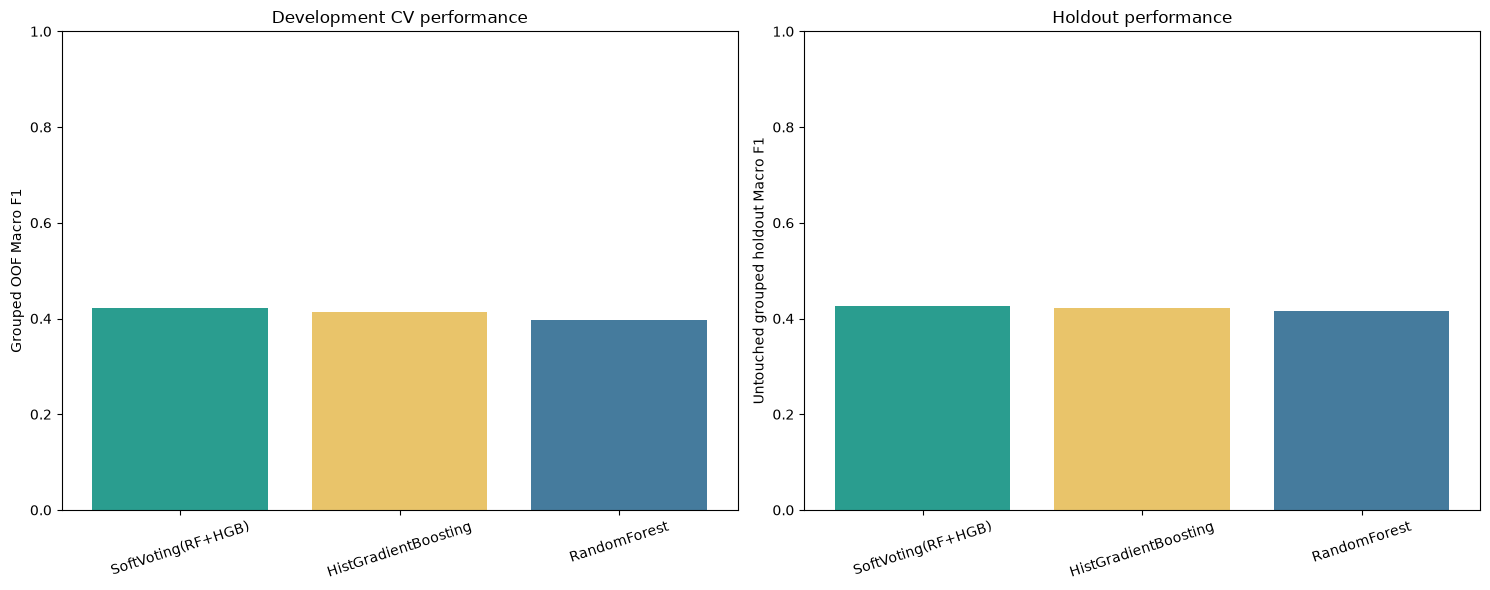

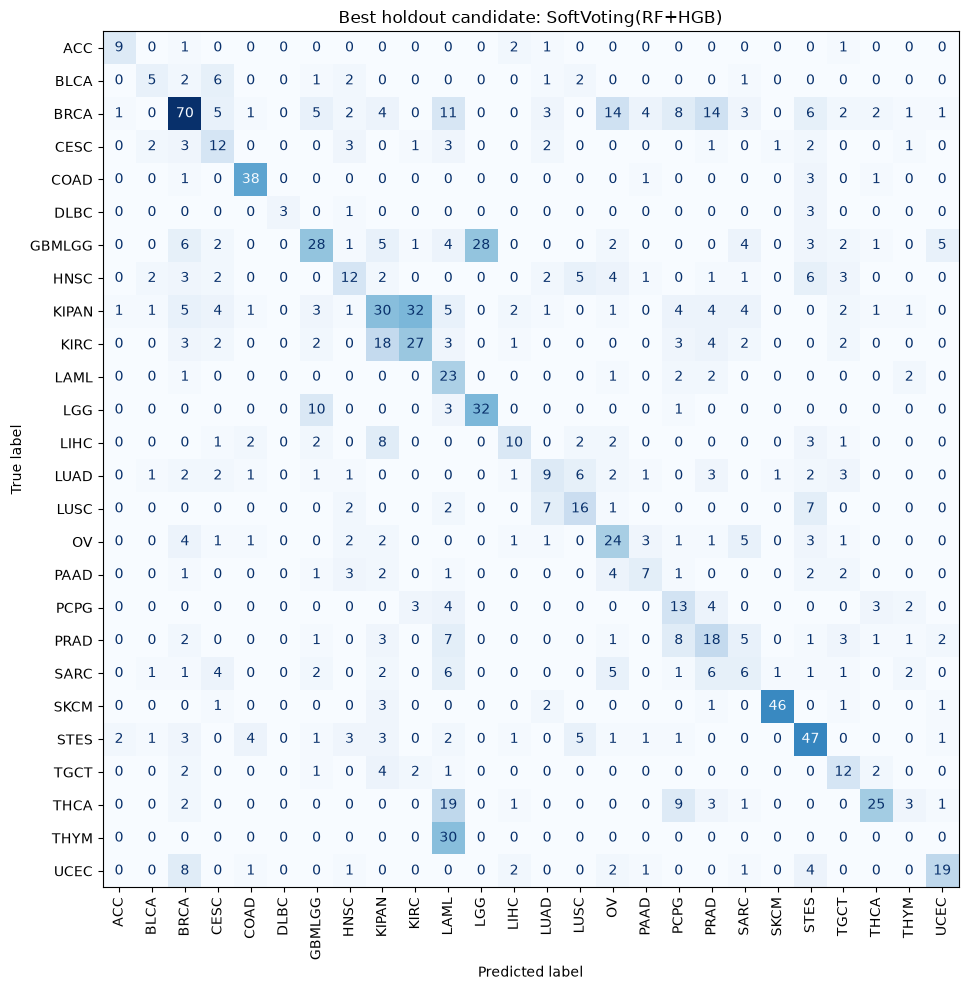

In [3]:
colors = {"RandomForest": "#457b9d", "HistGradientBoosting": "#e9c46a", "SoftVoting(RF+HGB)": "#2a9d8f"}
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].bar(
    comparison_table["model"],
    comparison_table["OOF Macro F1"],
    color=[colors[name] for name in comparison_table["model"]],
)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Grouped OOF Macro F1")
axes[0].set_title("Development CV performance")
axes[0].tick_params(axis="x", rotation=18)

axes[1].bar(
    comparison_table["model"],
    comparison_table["Holdout Macro F1"],
    color=[colors[name] for name in comparison_table["model"]],
)
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Untouched grouped holdout Macro F1")
axes[1].set_title("Holdout performance")
axes[1].tick_params(axis="x", rotation=18)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 10))
ConfusionMatrixDisplay.from_predictions(
    y_holdout,
    best_holdout_prediction,
    labels=class_labels,
    display_labels=class_labels,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title(f"Best holdout candidate: {best_model_name}")
fig.tight_layout()
plt.show()

### CV-홀드아웃 비교 시각화와 오류 확인

두 패널은 개발 데이터 OOF Macro F1과 미사용 그룹 홀드아웃 Macro F1을 나란히 표시합니다. 차이가 크면 모델 선택 또는 검증 점수의 변동이 큰 것일 수 있습니다. 혼동행렬은 OOF Macro F1로 선택된 후보가 홀드아웃에서 만든 예측의 암종 간 오류를 보여 줍니다. 이 결과에 따라 후보를 추천하되, 한 번의 분할 결과를 보편적인 성능 보장으로 해석하지 않습니다.

### Q&A
- 추가로 비교할 모델은 무엇인가요? RandomForest와 HistGradientBoosting이며, 두 모델의 균등 soft-voting 앙상블도 포함합니다.
- 어떤 모델/앙상블을 추천하나요? 실행 후 동일 grouped holdout에서 Macro F1이 가장 높은 후보를 일차 추천으로 삼고, grouped CV 점수와 fold 편차가 뒷받침하는지 함께 판단합니다. soft-voting이 두 개별 모델보다 일관되게 낫지 않다면 앙상블을 선택하지 않습니다.

### Data Analysis Key Findings
- 결과 표에는 grouped OOF Macro F1, fold 평균과 표준편차, 홀드아웃 Macro F1, 균형 정확도, weighted F1, 정확도와 학습 시간을 포함합니다.
- 데이터가 실행되기 전에는 비교 점수나 최적 후보를 단정하지 않습니다. 실제 추천은 위 표와 그래프를 실행해 확인한 결과에 따릅니다.

### Insights or Next Steps
- CV와 홀드아웃 양쪽에서 성능이 안정적인 후보를 우선하고, 분할에 따라 결과가 크게 달라지면 반복 grouped CV로 확인합니다.
- 앙상블이 유망하면 확률 평균 외에 OOF 예측으로 가중치를 검증하되, 홀드아웃 점수로 가중치를 반복 조정하지 마세요.